# 06 – Statistics for Data Science (S6)

**Course section:** Veri Bilimi için İstatistik — sampling, descriptive statistics, confidence intervals, distributions (Bernoulli, binomial, Poisson, normal) and hypothesis tests (one-sample t, proportion, independent and paired two-sample t, two-proportion / A-B, ANOVA, correlation) with assumption checks and non-parametric alternatives.

**Plan reviewed by ChatGPT (REVIEW #5, approved with changes).** Applied rules:
- **Welch** t-test and **Welch ANOVA** are the primary parametric tests; classical ANOVA is shown for comparison.
- Assumptions are judged with Q-Q plots, skewness/kurtosis, group sizes and **Brown–Forsythe** (median-centred Levene). Shapiro–Wilk is reported on small random subsamples only, never as a pass/fail gate: with n ≈ 37,000 it rejects even tiny deviations.
- Every test reports an **effect size and a 95% CI**; with this sample size almost everything is "significant", so practical size matters more than the p-value.
- **Holm** correction across the five main hypotheses H1–H5; post-hoc and subgroup tests get their own correction (Games–Howell, Holm).
- Mann–Whitney / Kruskal–Wallis test differences in **distributions** (stochastic ordering), not medians.
- Listings are not fully independent (one host can own many listings) → sensitivity check with **one random listing per host**.
- S6 uses the full data because it describes the historical snapshot; nothing here is fitted for the predictive model (S7 starts with the train/test split). All results are **associations, not causal effects**.

In [1]:
# --- Imports and settings ---
import sys
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportions_ztest, proportion_confint, confint_proportions_2indep
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))
from configs.config import RANDOM_STATE, TARGET

FIG_DIR = PROJECT_ROOT / "reports" / "figures"; TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200)
rng = np.random.default_rng(RANDOM_STATE)
def save(fig, name): fig.savefig(FIG_DIR / f"06_{name}.png", dpi=120, bbox_inches="tight")

df = pd.read_pickle(PROJECT_ROOT / "data" / "processed" / "ny_listings_enriched.pkl")
pos = df[df[TARGET] > 0].copy()
pos["log_price"] = np.log1p(pos[TARGET])
pos["district"] = pos["district"].astype(str); pos["room_type"] = pos["room_type"].astype(str)
ent = pos[pos["room_type"] == "Entire place"].copy()
print("price > 0:", len(pos), "| entire places:", len(ent))

price > 0: 36984 | entire places: 19397


In [2]:
# --- Small helpers for effect sizes ---
def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb - 1) * np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(a) - np.mean(b)) / sp

def rank_biserial(u, na, nb):
    """Rank-biserial correlation from Mann-Whitney U of sample a (positive: a tends to be larger)."""
    return 2 * u / (na * nb) - 1

def spearman_ci(r, n, alpha=0.05):
    """Fisher-z CI for Spearman's rho with the Bonett-Wright standard error."""
    z, se = np.arctanh(r), np.sqrt((1 + r ** 2 / 2) / (n - 3))
    q = stats.norm.ppf(1 - alpha / 2)
    return np.tanh(z - q * se), np.tanh(z + q * se)

results = []      # one row per main hypothesis, filled below

## 1. Sampling and confidence intervals
The file is close to a census of the snapshot, so we know the 'population' mean of log price. Drawing many random samples shows what a 95% confidence interval means.

Population mean log price: 4.6314  (≈ $102)
First sample: mean 4.6668, 95% CI [4.6010, 4.7325]
Coverage over 1000 samples of n=500: 0.964  (expected ≈ 0.95)
Standard error: theory 0.0320 vs. spread of sample means 0.0311


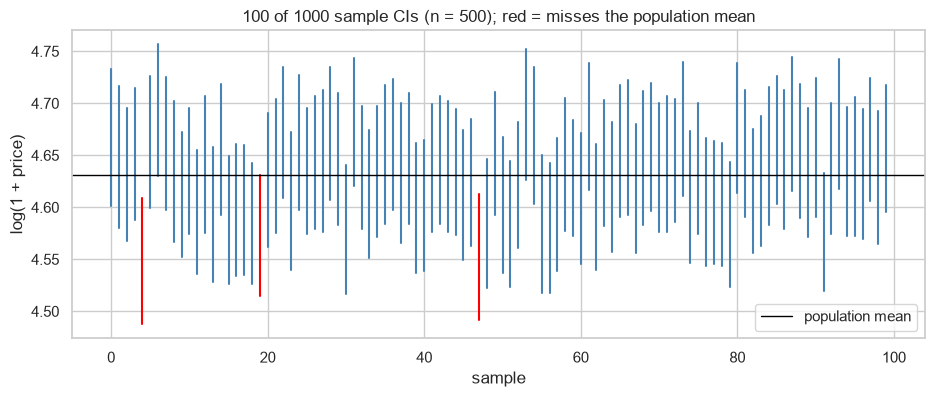

In [3]:
mu = pos["log_price"].mean()
values = pos["log_price"].to_numpy()
n, reps = 500, 1000
idx = rng.integers(0, len(values), size=(reps, n))
samples = values[idx]
means, sds = samples.mean(axis=1), samples.std(axis=1, ddof=1)
half = stats.t.ppf(0.975, n - 1) * sds / np.sqrt(n)
covered = (means - half <= mu) & (mu <= means + half)
print(f"Population mean log price: {mu:.4f}  (≈ ${np.expm1(mu):.0f})")
print(f"First sample: mean {means[0]:.4f}, 95% CI [{means[0]-half[0]:.4f}, {means[0]+half[0]:.4f}]")
print(f"Coverage over {reps} samples of n={n}: {covered.mean():.3f}  (expected ≈ 0.95)")
print(f"Standard error: theory {values.std(ddof=1)/np.sqrt(n):.4f} vs. spread of sample means {means.std(ddof=1):.4f}")

fig, ax = plt.subplots(figsize=(11, 4))
k = 100
for i in range(k):
    ax.plot([i, i], [means[i] - half[i], means[i] + half[i]], color="steelblue" if covered[i] else "red", lw=1.5)
ax.axhline(mu, color="black", lw=1, label="population mean")
ax.set(title=f"100 of {reps} sample CIs (n = {n}); red = misses the population mean", xlabel="sample", ylabel="log(1 + price)")
ax.legend(); save(fig, "01_ci_coverage"); plt.show()

In [4]:
# 95% CIs per borough: mean log price (t) and Superhost share (Wilson)
rows = []
for b, g in pos.groupby("district"):
    m, se = g["log_price"].mean(), g["log_price"].std(ddof=1) / np.sqrt(len(g))
    lo, hi = stats.t.interval(0.95, len(g) - 1, loc=m, scale=se)
    sh = g["host_is_superhost"].dropna()
    slo, shi = proportion_confint(sh.sum(), len(sh), method="wilson")
    rows.append({"borough": b, "n": len(g), "mean_log": m, "ci_low": lo, "ci_high": hi,
                 "typical_price": np.expm1(m), "superhost_share": sh.mean(), "sh_ci_low": slo, "sh_ci_high": shi})
pd.DataFrame(rows).set_index("borough").round(3)

,n,mean_log,ci_low,ci_high,typical_price,superhost_share,sh_ci_low,sh_ci_high
borough,,,,,,,,
Bronx,991,4.297,4.258,4.336,72.479,0.271,0.245,0.300
Brooklyn,14472,4.519,4.508,4.530,90.743,0.203,0.197,0.210
Manhattan,16528,4.852,4.841,4.863,126.969,0.158,0.152,0.163
Queens,4704,4.285,4.266,4.304,71.598,0.220,0.209,0.232
Staten Island,289,4.442,4.367,4.518,83.981,0.408,0.353,0.466


## 2. Probability distributions

Bernoulli(p = 0.299): mean = 0.299, variance = p(1-p) = 0.209


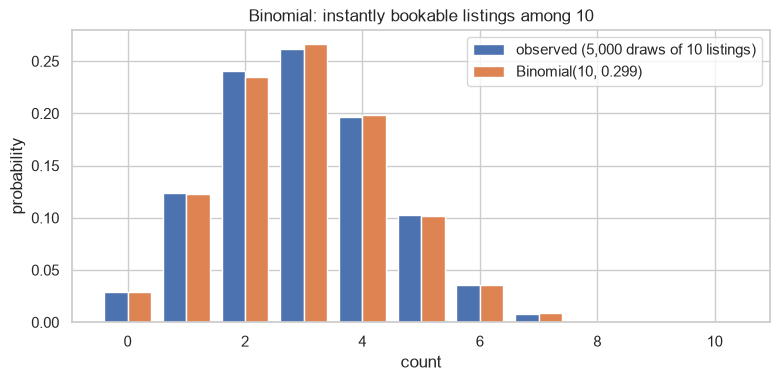

P(at least 5 of 10) – observed: 0.148 | binomial: 0.148


In [5]:
# Bernoulli: is a listing instantly bookable?
p_ib = pos["instant_bookable"].astype(float).mean()
print(f"Bernoulli(p = {p_ib:.3f}): mean = {p_ib:.3f}, variance = p(1-p) = {p_ib*(1-p_ib):.3f}")

# Binomial: number of instantly bookable listings among 10 random listings
draws = pos["instant_bookable"].astype(int).to_numpy()[rng.integers(0, len(pos), size=(5000, 10))].sum(axis=1)
k = np.arange(11)
emp = np.bincount(draws, minlength=11) / len(draws)
theo = stats.binom.pmf(k, 10, p_ib)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(k - 0.2, emp, width=0.4, label="observed (5,000 draws of 10 listings)")
ax.bar(k + 0.2, theo, width=0.4, label=f"Binomial(10, {p_ib:.3f})")
ax.set(title="Binomial: instantly bookable listings among 10", xlabel="count", ylabel="probability"); ax.legend()
save(fig, "02_binomial"); plt.show()
print("P(at least 5 of 10) – observed:", round((draws >= 5).mean(), 3), "| binomial:", round(stats.binom.sf(4, 10, p_ib), 3))

mean = 2.75, variance = 91.64, dispersion (var/mean) = 33.3  -> Poisson needs var ≈ mean
share of zeros: observed 0.641 vs Poisson 0.064


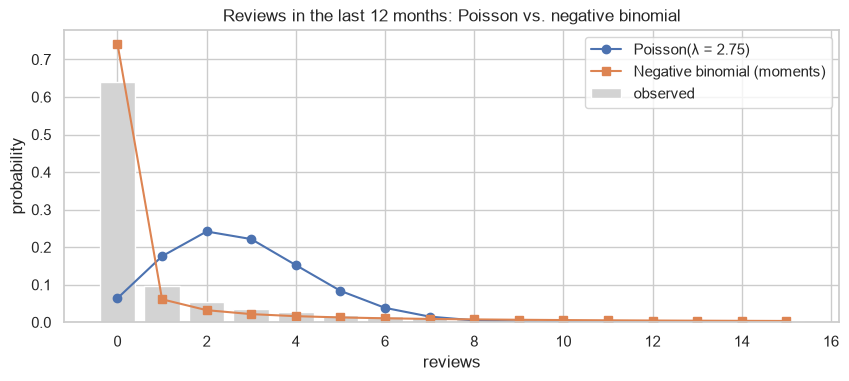

In [6]:
# Poisson: reviews in the last 12 months per listing
y = pos["reviews_last_12m"].to_numpy()
lam, var = y.mean(), y.var(ddof=1)
print(f"mean = {lam:.2f}, variance = {var:.2f}, dispersion (var/mean) = {var/lam:.1f}  -> Poisson needs var ≈ mean")
print(f"share of zeros: observed {np.mean(y == 0):.3f} vs Poisson {stats.poisson.pmf(0, lam):.3f}")

# Negative binomial (method of moments) as the usual fix for overdispersion
r = lam ** 2 / (var - lam); p_nb = r / (r + lam)
k = np.arange(0, 16)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(k, [np.mean(y == i) for i in k], color="lightgray", label="observed")
ax.plot(k, stats.poisson.pmf(k, lam), "o-", label=f"Poisson(λ = {lam:.2f})")
ax.plot(k, stats.nbinom.pmf(k, r, p_nb), "s-", label="Negative binomial (moments)")
ax.set(title="Reviews in the last 12 months: Poisson vs. negative binomial", xlabel="reviews", ylabel="probability"); ax.legend()
save(fig, "03_poisson_vs_negbin"); plt.show()

skewness 0.75, excess kurtosis 1.79
Shapiro-Wilk on a random subsample of 500 (information only): ShapiroResult(statistic=0.9819084032119959, pvalue=7.083213419211027e-06)


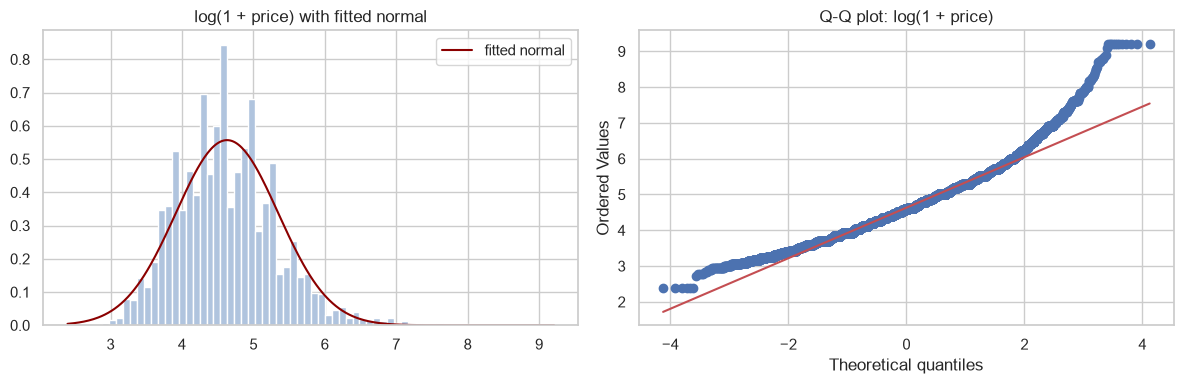

share within 1 sd: 0.716 (normal 0.683) | within 2 sd: 0.962 (normal 0.954)


In [7]:
# Normal: is log price approximately normal?
lp = pos["log_price"]
print(f"skewness {lp.skew():.2f}, excess kurtosis {lp.kurt():.2f}")
sub = lp.sample(500, random_state=RANDOM_STATE)
print("Shapiro-Wilk on a random subsample of 500 (information only):", stats.shapiro(sub))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lp, bins=70, density=True, color="lightsteelblue")
xs = np.linspace(lp.min(), lp.max(), 300)
axes[0].plot(xs, stats.norm.pdf(xs, lp.mean(), lp.std()), color="darkred", label="fitted normal")
axes[0].set(title="log(1 + price) with fitted normal"); axes[0].legend()
stats.probplot(lp, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot: log(1 + price)")
plt.tight_layout(); save(fig, "04_normal_check"); plt.show()

within_1sd = ((lp - lp.mean()).abs() <= lp.std()).mean()
within_2sd = ((lp - lp.mean()).abs() <= 2 * lp.std()).mean()
print(f"share within 1 sd: {within_1sd:.3f} (normal 0.683) | within 2 sd: {within_2sd:.3f} (normal 0.954)")

## 3. One-sample tests on a random sample (H0 true by construction)
We test a sample of 200 listings against the known full-data values. A correct test should usually **not** reject here.

In [8]:
s = pos.sample(200, random_state=RANDOM_STATE)
t1 = stats.ttest_1samp(s["log_price"], popmean=mu)
print(f"One-sample t: H0 mean log price = {mu:.3f}; sample mean {s['log_price'].mean():.3f}; "
      f"t = {t1.statistic:.2f}, p = {t1.pvalue:.3f}, 95% CI {np.round(t1.confidence_interval(), 3)}")

p0 = pos["host_is_superhost"].dropna().mean()
sh = s["host_is_superhost"].dropna()
z, pz = proportions_ztest(sh.sum(), len(sh), value=p0)
print(f"One-sample proportion z: H0 Superhost share = {p0:.3f}; sample {sh.mean():.3f} (n = {len(sh)}); z = {z:.2f}, p = {pz:.3f}")

One-sample t: H0 mean log price = 4.631; sample mean 4.644; t = 0.27, p = 0.789, 95% CI [4.552 4.735]
One-sample proportion z: H0 Superhost share = 0.188; sample 0.205 (n = 200); z = 0.58, p = 0.563


## 4. H1 – Entire place vs. private room (independent two-sample)
**H0:** the mean log price is the same for entire places and private rooms. **H1:** it differs.

In [9]:
a = pos.loc[pos["room_type"] == "Entire place", "log_price"].to_numpy()
b = pos.loc[pos["room_type"] == "Private room", "log_price"].to_numpy()
w = stats.ttest_ind(a, b, equal_var=False)
mw = stats.mannwhitneyu(a, b, alternative="two-sided")
bf = stats.levene(a, b, center="median")
d = cohens_d(a, b); rb = rank_biserial(mw.statistic, len(a), len(b))
ci = w.confidence_interval()
print(f"n = {len(a):,} vs {len(b):,} | skew {stats.skew(a):.2f} / {stats.skew(b):.2f} | Brown-Forsythe p = {bf.pvalue:.3g}")
print(f"Welch t = {w.statistic:.1f}, df = {w.df:.0f}, p = {w.pvalue:.3g}; mean diff (log) = {a.mean()-b.mean():.3f}, 95% CI [{ci.low:.3f}, {ci.high:.3f}]")
print(f"  -> entire places cost about {np.exp(a.mean()-b.mean()):.2f}x private rooms (CI {np.exp(ci.low):.2f}-{np.exp(ci.high):.2f}x)")
print(f"Mann-Whitney U p = {mw.pvalue:.3g}; rank-biserial r = {rb:.3f}; Cohen's d = {d:.2f}")
results.append({"hypothesis": "H1 entire vs private (log price)", "test": "Welch t", "statistic": w.statistic,
                "p": w.pvalue, "effect": f"d = {d:.2f}; ratio {np.exp(a.mean()-b.mean()):.2f}x",
                "nonparametric": f"Mann-Whitney p = {mw.pvalue:.2g}, r_rb = {rb:.2f}"})

n = 19,397 vs 16,630 | skew 1.15 / 1.59 | Brown-Forsythe p = 4.57e-17
Welch t = 134.9, df = 35670, p = 0; mean diff (log) = 0.820, 95% CI [0.808, 0.832]
  -> entire places cost about 2.27x private rooms (CI 2.24-2.30x)
Mann-Whitney U p = 0; rank-biserial r = 0.742; Cohen's d = 1.42


## 5. H2 – Price differences between boroughs **within entire places** (ANOVA)
**H0:** the mean log price of entire places is the same in all five boroughs.

                     n  mean_log     sd   skew  kurtosis  typical_price
Bronx            368.0     4.736  0.565  1.099     3.164        112.989
Brooklyn        7206.0     4.942  0.528  1.246     4.298        138.990
Manhattan      10014.0     5.118  0.622  1.033     2.674        166.031
Queens          1662.0     4.818  0.554  1.576     7.163        122.770
Staten Island    147.0     4.796  0.562  1.191     2.727        120.067

Brown-Forsythe (median-centred Levene): LeveneResult(statistic=43.33795773639701, pvalue=2.9069867623618803e-36)
Shapiro on 500 random values per borough (information only): {'Bronx': 0.0, 'Brooklyn': 0.0, 'Manhattan': 0.0, 'Queens': 0.0, 'Staten Island': 0.0}


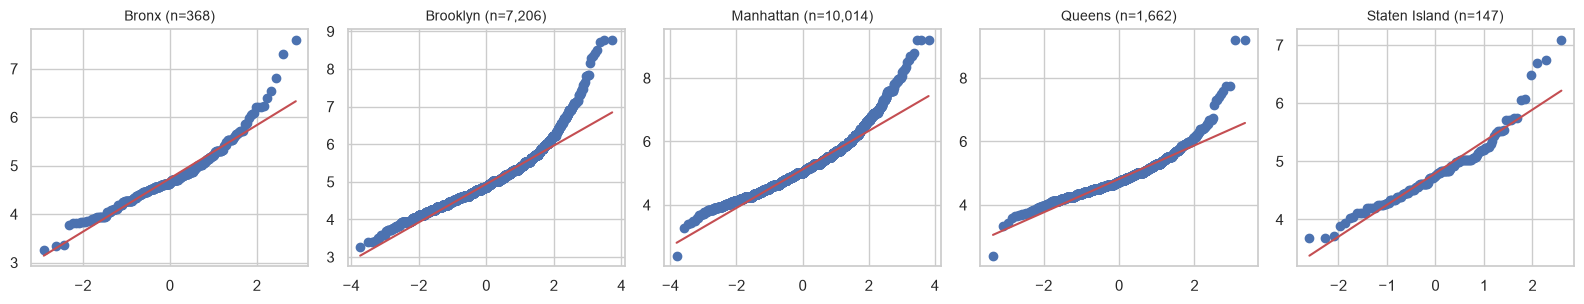

In [10]:
groups = {b: g["log_price"].to_numpy() for b, g in ent.groupby("district")}
names = list(groups)
desc = pd.DataFrame({b: {"n": len(v), "mean_log": v.mean(), "sd": v.std(ddof=1), "skew": stats.skew(v),
                         "kurtosis": stats.kurtosis(v), "typical_price": np.expm1(v.mean())} for b, v in groups.items()}).T
print(desc.round(3))
print("\nBrown-Forsythe (median-centred Levene):", stats.levene(*groups.values(), center="median"))
print("Shapiro on 500 random values per borough (information only):",
      {b: round(stats.shapiro(rng.choice(v, min(500, len(v)), replace=False)).pvalue, 4) for b, v in groups.items()})

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, (b, v) in zip(axes, groups.items()):
    stats.probplot(v, dist="norm", plot=ax); ax.set_title(f"{b} (n={len(v):,})", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); save(fig, "05_h2_qq_by_borough"); plt.show()

In [11]:
def welch_anova(groups):
    """Welch's one-way ANOVA (does not assume equal variances)."""
    n = np.array([len(g) for g in groups]); m = np.array([np.mean(g) for g in groups]); v = np.array([np.var(g, ddof=1) for g in groups])
    k = len(groups); w = n / v; W = w.sum(); mw = (w * m).sum() / W
    A = (w * (m - mw) ** 2).sum() / (k - 1)
    tmp = ((1 - w / W) ** 2 / (n - 1)).sum()
    F = A / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    df1, df2 = k - 1, (k ** 2 - 1) / (3 * tmp)
    return F, df1, df2, stats.f.sf(F, df1, df2)

gl = list(groups.values())
F_w, df1, df2, p_w = welch_anova(gl)
classic = stats.f_oneway(*gl)
ag = stats.alexandergovern(*gl)
kw = stats.kruskal(*gl)
allv = np.concatenate(gl); grand = allv.mean()
ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in gl); ss_t = ((allv - grand) ** 2).sum()
eta2 = ss_b / ss_t
omega2 = (ss_b - (len(gl) - 1) * (ss_t - ss_b) / (len(allv) - len(gl))) / (ss_t + (ss_t - ss_b) / (len(allv) - len(gl)))
eps2 = kw.statistic / (len(allv) - 1)
print(f"Welch ANOVA: F({df1}, {df2:.0f}) = {F_w:.1f}, p = {p_w:.3g}   <- primary")
print(f"Classical ANOVA: F = {classic.statistic:.1f}, p = {classic.pvalue:.3g} | Alexander-Govern: A = {ag.statistic:.1f}, p = {ag.pvalue:.3g}")
print(f"Kruskal-Wallis: H = {kw.statistic:.1f}, p = {kw.pvalue:.3g}, epsilon² = {eps2:.3f}")
print(f"Effect size: eta² = {eta2:.3f}, omega² = {omega2:.3f}  (share of log-price variance explained by borough)")
results.append({"hypothesis": "H2 boroughs within entire places", "test": "Welch ANOVA", "statistic": F_w, "p": p_w,
                "effect": f"eta² = {eta2:.3f}", "nonparametric": f"Kruskal-Wallis p = {kw.pvalue:.2g}, eps² = {eps2:.3f}"})

Welch ANOVA: F(4, 806) = 181.4, p = 8.54e-111   <- primary
Classical ANOVA: F = 181.4, p = 7.46e-153 | Alexander-Govern: A = 702.1, p = 1.24e-150
Kruskal-Wallis: H = 800.9, p = 5e-172, epsilon² = 0.041
Effect size: eta² = 0.036, omega² = 0.036  (share of log-price variance explained by borough)


In [12]:
# Post-hoc: Games-Howell (unequal variances) and Tukey HSD (classical), both control the family-wise error
rows = []
for (i, ai), (j, aj) in combinations(groups.items(), 2):
    ni, nj, vi, vj = len(ai), len(aj), ai.var(ddof=1), aj.var(ddof=1)
    diff = ai.mean() - aj.mean()
    se2 = vi / ni + vj / nj
    dfw = se2 ** 2 / ((vi / ni) ** 2 / (ni - 1) + (vj / nj) ** 2 / (nj - 1))
    q = abs(diff) / np.sqrt(se2 / 2)
    p_gh = stats.studentized_range.sf(q, len(groups), dfw)
    rows.append({"pair": f"{i} - {j}", "diff_log": diff, "price_ratio": np.exp(diff), "p_games_howell": p_gh})
gh = pd.DataFrame(rows).sort_values("diff_log", key=abs, ascending=False)
tk = stats.tukey_hsd(*gl)
gh["p_tukey"] = [tk.pvalue[names.index(p.split(" - ")[0]), names.index(p.split(" - ")[1])] for p in gh["pair"]]
gh.round(4)

,pair,diff_log,price_ratio,p_games_howell,p_tukey
1,Bronx - Manhattan,-0.3821,0.6824,0.0000,0.0000
8,Manhattan - Staten Island,0.3218,1.3797,0.0000,0.0000
7,Manhattan - Queens,0.2998,1.3495,0.0000,0.0000
0,Bronx - Brooklyn,-0.2055,0.8143,0.0000,0.0000
4,Brooklyn - Manhattan,-0.1766,0.8381,0.0000,0.0000
6,Brooklyn - Staten Island,0.1452,1.1563,0.0190,0.0228
5,Brooklyn - Queens,0.1231,1.1310,0.0000,0.0000
2,Bronx - Queens,-0.0823,0.9210,0.0840,0.1004
3,Bronx - Staten Island,-0.0602,0.9415,0.8082,0.8260
9,Queens - Staten Island,0.0221,1.0223,0.9909,0.9921


## 6. H3 – Superhost share: Manhattan vs. the other boroughs (A/B two-proportion test)
**H0:** the Superhost share is the same in Manhattan and in the other four boroughs.

In [13]:
shd = df[df["host_is_superhost"].notna()].copy(); shd["district"] = shd["district"].astype(str)
man = shd["district"] == "Manhattan"
c1, n1 = int(shd.loc[man, "host_is_superhost"].sum()), int(man.sum())
c2, n2 = int(shd.loc[~man, "host_is_superhost"].sum()), int((~man).sum())
z, pz = proportions_ztest([c1, c2], [n1, n2])
lo, hi = confint_proportions_2indep(c1, n1, c2, n2)
p1, p2 = c1 / n1, c2 / n2
h = 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))      # Cohen's h
print(f"Manhattan: {c1:,} / {n1:,} = {p1:.3f} | other boroughs: {c2:,} / {n2:,} = {p2:.3f}")
print(f"z = {z:.2f}, p = {pz:.3g}; difference = {p1-p2:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]; Cohen's h = {h:.2f}")

ct = pd.crosstab(shd["district"], shd["host_is_superhost"])
chi2, pc, dof, _ = stats.chi2_contingency(ct)
cramer_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
print(f"Chi-square (5 boroughs x Superhost): chi² = {chi2:.1f}, df = {dof}, p = {pc:.3g}, Cramér's V = {cramer_v:.3f}")
results.append({"hypothesis": "H3 Superhost share Manhattan vs others", "test": "two-proportion z", "statistic": z, "p": pz,
                "effect": f"diff = {p1-p2:.3f}; h = {h:.2f}", "nonparametric": f"chi² (5 boroughs) p = {pc:.2g}, V = {cramer_v:.2f}"})

Manhattan: 2,609 / 16,545 = 0.158 | other boroughs: 4,362 / 20,449 = 0.213
z = -13.60, p = 3.91e-42; difference = -0.056, 95% CI [-0.063, -0.048]; Cohen's h = -0.14
Chi-square (5 boroughs x Superhost): chi² = 289.7, df = 4, p = 1.81e-61, Cramér's V = 0.088


## 7. H4 – Superhost vs. non-Superhost price **within entire places**
**H0:** mean log price does not differ by Superhost status. Then: per-borough comparisons (Holm) and an **adjusted OLS** with HC3 robust standard errors.

In [14]:
e4 = ent[ent["host_is_superhost"].notna()].copy()
s_ = e4.loc[e4["host_is_superhost"] == True, "log_price"].to_numpy()
n_ = e4.loc[e4["host_is_superhost"] == False, "log_price"].to_numpy()
w4 = stats.ttest_ind(s_, n_, equal_var=False); ci4 = w4.confidence_interval()
mw4 = stats.mannwhitneyu(s_, n_, alternative="two-sided")
d4 = cohens_d(s_, n_); rb4 = rank_biserial(mw4.statistic, len(s_), len(n_))
print(f"n = {len(s_):,} Superhost vs {len(n_):,} not | Welch t = {w4.statistic:.2f}, p = {w4.pvalue:.3g}")
print(f"mean diff (log) = {s_.mean()-n_.mean():.3f}, 95% CI [{ci4.low:.3f}, {ci4.high:.3f}] -> ratio {np.exp(s_.mean()-n_.mean()):.3f}")
print(f"Cohen's d = {d4:.3f}; Mann-Whitney p = {mw4.pvalue:.3g}, rank-biserial = {rb4:.3f}")
results.append({"hypothesis": "H4 Superhost vs not (entire places)", "test": "Welch t", "statistic": w4.statistic, "p": w4.pvalue,
                "effect": f"d = {d4:.2f}; ratio {np.exp(s_.mean()-n_.mean()):.3f}", "nonparametric": f"Mann-Whitney p = {mw4.pvalue:.2g}, r_rb = {rb4:.2f}"})

rows = []
for b, g in e4.groupby("district"):
    x, y = g.loc[g["host_is_superhost"] == True, "log_price"], g.loc[g["host_is_superhost"] == False, "log_price"]
    t = stats.ttest_ind(x, y, equal_var=False)
    rows.append({"borough": b, "n_super": len(x), "n_not": len(y), "ratio": np.exp(x.mean() - y.mean()), "p_welch": t.pvalue})
strat = pd.DataFrame(rows)
strat["p_holm"] = multipletests(strat["p_welch"], method="holm")[1]
strat.round(4)

n = 3,887 Superhost vs 15,504 not | Welch t = -5.32, p = 1.06e-07
mean diff (log) = -0.055, 95% CI [-0.075, -0.035] -> ratio 0.946
Cohen's d = -0.093; Mann-Whitney p = 8.65e-11, rank-biserial = -0.067


,borough,n_super,n_not,ratio,p_welch,p_holm
0,Bronx,102,266,0.9779,0.7017,0.8462
1,Brooklyn,1666,5538,1.0182,0.2074,0.6222
2,Manhattan,1578,8433,0.9353,0.0001,0.0006
3,Queens,479,1182,1.0240,0.4231,0.8462
4,Staten Island,62,85,0.8105,0.0149,0.0595


Superhost coefficient = -0.055 (95% CI -0.072 to -0.037), p = 1.19e-09
  -> adjusted price ratio 0.947 (CI 0.930-0.964); adjusted R² = 0.208, n = 19,391
VIF: {'superhost': 1.02, 'accommodates': 1.03, 'district_Bronx': 1.02, 'district_Brooklyn': 1.1, 'district_Queens': 1.09, 'district_Staten Island': 1.01}


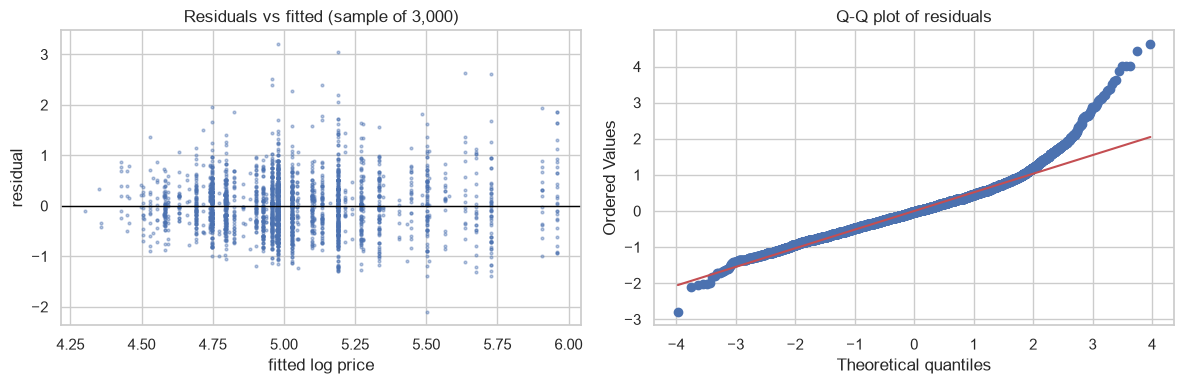

,coef,ci_low,ci_high,p
Intercept,4.8258,4.7779,4.8737,0.0
"C(district, Treatment('Manhattan'))[T.Bronx]",-0.4755,-0.5266,-0.4245,0.0
"C(district, Treatment('Manhattan'))[T.Brooklyn]",-0.2324,-0.2483,-0.2165,0.0
"C(district, Treatment('Manhattan'))[T.Queens]",-0.3966,-0.4226,-0.3706,0.0
"C(district, Treatment('Manhattan'))[T.Staten Island]",-0.4699,-0.5470,-0.3928,0.0
C(guests)[T.2],0.1538,0.1048,0.2028,0.0
C(guests)[T.3],0.2029,0.1525,0.2533,0.0
C(guests)[T.4],0.3644,0.3142,0.4147,0.0
C(guests)[T.5],0.5066,0.4505,0.5627,0.0
C(guests)[T.6],0.6764,0.6200,0.7329,0.0


In [15]:
# Adjusted comparison: log price ~ Superhost + borough + capacity (categorical, 8+ grouped), HC3 robust SEs
e4["superhost"] = e4["host_is_superhost"].astype(int)
e4["guests"] = e4["accommodates"].clip(upper=8).astype(int).astype(str)
ols = smf.ols("log_price ~ superhost + C(district, Treatment('Manhattan')) + C(guests)", data=e4).fit(cov_type="HC3")
b_sh, (lo_sh, hi_sh) = ols.params["superhost"], ols.conf_int().loc["superhost"]
print(f"Superhost coefficient = {b_sh:.3f} (95% CI {lo_sh:.3f} to {hi_sh:.3f}), p = {ols.pvalues['superhost']:.3g}")
print(f"  -> adjusted price ratio {np.exp(b_sh):.3f} (CI {np.exp(lo_sh):.3f}-{np.exp(hi_sh):.3f}); adjusted R² = {ols.rsquared_adj:.3f}, n = {int(ols.nobs):,}")
coef = pd.DataFrame({"coef": ols.params, "ci_low": ols.conf_int()[0], "ci_high": ols.conf_int()[1], "p": ols.pvalues}).round(4)
coef.to_csv(TABLE_DIR / "06_h4_adjusted_ols.csv")

# Multicollinearity check on a numeric version of the design
# Manhattan is the reference (as in the OLS); a tiny reference group (Bronx) would inflate the dummies' VIF artificially
X = pd.get_dummies(e4[["superhost", "accommodates", "district"]], columns=["district"], dtype=float).drop(columns="district_Manhattan")
X.insert(0, "const", 1.0)
print("VIF:", {c: round(variance_inflation_factor(X.values, i), 2) for i, c in enumerate(X.columns) if c != "const"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
smp = rng.choice(len(ols.resid), 3000, replace=False)
axes[0].scatter(ols.fittedvalues.iloc[smp], ols.resid.iloc[smp], s=4, alpha=.4); axes[0].axhline(0, color="black", lw=1)
axes[0].set(title="Residuals vs fitted (sample of 3,000)", xlabel="fitted log price", ylabel="residual")
stats.probplot(ols.resid, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot of residuals")
plt.tight_layout(); save(fig, "06_h4_ols_residuals"); plt.show()
coef

In [16]:
# Sensitivity (REVIEW #6): standard errors clustered by host, because one host can own many listings
ols_cl = smf.ols("log_price ~ superhost + C(district, Treatment('Manhattan')) + C(guests)", data=e4).fit(
    cov_type="cluster", cov_kwds={"groups": e4["host_id"]})
lo_c, hi_c = ols_cl.conf_int().loc["superhost"]
print(f"Host-clustered SE: superhost coef {ols_cl.params['superhost']:.3f}, 95% CI {lo_c:.3f} to {hi_c:.3f}, p = {ols_cl.pvalues['superhost']:.3g}")
print(f"SE: HC3 {ols.bse['superhost']:.4f} vs host-clustered {ols_cl.bse['superhost']:.4f} ({e4['host_id'].nunique():,} hosts)")

Host-clustered SE: superhost coef -0.055, 95% CI -0.100 to -0.009, p = 0.0186
SE: HC3 0.0090 vs host-clustered 0.0233 (15,617 hosts)


## 8. H5 – Capacity and price (correlation)
**H0:** there is no correlation between `accommodates` and log price.

In [17]:
x, y = pos["accommodates"], pos["log_price"]
pr = stats.pearsonr(x, y); pci = pr.confidence_interval()
sr = stats.spearmanr(x, y); sci = spearman_ci(sr.statistic, len(x))
xe, ye = ent["accommodates"], ent["log_price"]
sr_e = stats.spearmanr(xe, ye); sci_e = spearman_ci(sr_e.statistic, len(xe))
print(f"All listings (n = {len(x):,}): Pearson r = {pr.statistic:.3f} [{pci.low:.3f}, {pci.high:.3f}], p = {pr.pvalue:.3g}; "
      f"Spearman rho = {sr.statistic:.3f} [{sci[0]:.3f}, {sci[1]:.3f}]")
print(f"Entire places only (n = {len(xe):,}): Spearman rho = {sr_e.statistic:.3f} [{sci_e[0]:.3f}, {sci_e[1]:.3f}]")
print(f"r² = {pr.statistic**2:.3f}: capacity alone explains about {100*pr.statistic**2:.0f}% of the variance of log price")
results.append({"hypothesis": "H5 accommodates vs log price", "test": "Pearson r", "statistic": pr.statistic, "p": pr.pvalue,
                "effect": f"r = {pr.statistic:.2f}; r² = {pr.statistic**2:.2f}", "nonparametric": f"Spearman rho = {sr.statistic:.2f}"})

All listings (n = 36,984): Pearson r = 0.525 [0.518, 0.533], p = 0; Spearman rho = 0.554 [0.546, 0.561]
Entire places only (n = 19,397): Spearman rho = 0.317 [0.304, 0.330]
r² = 0.276: capacity alone explains about 28% of the variance of log price


## 9. Paired test – cleanliness vs. location score of the same listing
Scores are ordinal (2–10) and treated approximately as interval; only listings with both scores are used.

In [18]:
pr_df = df[["review_scores_cleanliness", "review_scores_location"]].dropna()
dlt = pr_df["review_scores_location"] - pr_df["review_scores_cleanliness"]
tp = stats.ttest_rel(pr_df["review_scores_location"], pr_df["review_scores_cleanliness"])
wx = stats.wilcoxon(dlt[dlt != 0])
nz = dlt[dlt != 0]; ranks = stats.rankdata(nz.abs())
r_pairs = (ranks[nz > 0].sum() - ranks[nz < 0].sum()) / ranks.sum()
print(f"n pairs = {len(pr_df):,}; mean location {pr_df['review_scores_location'].mean():.3f} vs cleanliness {pr_df['review_scores_cleanliness'].mean():.3f}")
print(f"differences: {np.mean(dlt > 0):.3f} location higher, {np.mean(dlt == 0):.3f} equal, {np.mean(dlt < 0):.3f} cleanliness higher")
print(f"Paired t = {tp.statistic:.1f}, p = {tp.pvalue:.3g}, 95% CI of mean diff {np.round(tp.confidence_interval(), 3)}; d_z = {dlt.mean()/dlt.std(ddof=1):.2f}")
print(f"Wilcoxon signed-rank (non-zero pairs, n = {len(nz):,}) p = {wx.pvalue:.3g}; matched-pairs rank-biserial = {r_pairs:.2f}")

n pairs = 26,735; mean location 9.600 vs cleanliness 9.269
differences: 0.316 location higher, 0.560 equal, 0.125 cleanliness higher
Paired t = 49.5, p = 0, 95% CI of mean diff [0.317 0.343]; d_z = 0.30
Wilcoxon signed-rank (non-zero pairs, n = 11,772) p = 0; matched-pairs rank-biserial = 0.50


## 10. Sensitivity: one random listing per host
Hosts with many listings make observations dependent. We repeat H1 and H4 with one random listing per host.

In [19]:
rows = []
for seed in range(20):                                  # repeat with 20 seeds (REVIEW #6)
    one = pos.groupby("host_id", group_keys=False).sample(1, random_state=seed)
    a1 = one.loc[one["room_type"] == "Entire place", "log_price"]; b1 = one.loc[one["room_type"] == "Private room", "log_price"]
    e1 = one[(one["room_type"] == "Entire place") & one["host_is_superhost"].notna()]
    s1, n1_ = e1.loc[e1["host_is_superhost"] == True, "log_price"], e1.loc[e1["host_is_superhost"] == False, "log_price"]
    rows.append({"seed": seed, "H1_ratio": np.exp(a1.mean() - b1.mean()), "H1_d": cohens_d(a1, b1),
                 "H4_ratio": np.exp(s1.mean() - n1_.mean()), "H4_d": cohens_d(s1, n1_),
                 "H4_p": stats.ttest_ind(s1, n1_, equal_var=False).pvalue})
sens = pd.DataFrame(rows)
print(f"Listings kept per draw: {len(one):,} of {len(pos):,} (one per host)")
sens.drop(columns="seed").describe().loc[["mean", "min", "max"]].round(4)

Listings kept per draw: 26,742 of 36,984 (one per host)


,H1_ratio,H1_d,H4_ratio,H4_d,H4_p
mean,2.1706,1.3814,0.9560,-0.0771,0.0002
min,2.1670,1.3770,0.9531,-0.0824,0.0000
max,2.1745,1.3855,0.9603,-0.0696,0.0006


## 11. Summary of the main hypotheses (Holm-corrected)
Three separate multiple-testing families are used:
1. **Primary family H1–H5** → Holm (table below).
2. **H2 post-hoc borough pairs** → Games–Howell (primary) / Tukey HSD (section 5).
3. **H4 per-borough comparisons** → Holm within the five boroughs (section 7).
Everything else (sampling demo, one-sample tests, paired test, sensitivity checks) is a course demonstration or exploratory check and is not part of a family.

In [20]:
res = pd.DataFrame(results)
res["p_holm"] = multipletests(res["p"], method="holm")[1]
res["reject_H0 (alpha 0.05)"] = res["p_holm"] < 0.05
res.to_csv(TABLE_DIR / "06_hypothesis_results.csv", index=False)
res[["hypothesis", "test", "statistic", "p", "p_holm", "reject_H0 (alpha 0.05)", "effect", "nonparametric"]]

,hypothesis,test,statistic,p,p_holm,reject_H0 (alpha 0.05),effect,nonparametric
0,H1 entire vs private (log price),Welch t,134.861442,0.000000e+00,0.000000e+00,True,d = 1.42; ratio 2.27x,"Mann-Whitney p = 0, r_rb = 0.74"
1,H2 boroughs within entire places,Welch ANOVA,181.417246,8.544488e-111,2.563346e-110,True,eta² = 0.036,"Kruskal-Wallis p = 5e-172, eps² = 0.041"
2,H3 Superhost share Manhattan vs others,two-proportion z,-13.601651,3.914965e-42,7.829930e-42,True,diff = -0.056; h = -0.14,"chi² (5 boroughs) p = 1.8e-61, V = 0.09"
3,H4 Superhost vs not (entire places),Welch t,-5.321593,1.064816e-07,1.064816e-07,True,d = -0.09; ratio 0.946,"Mann-Whitney p = 8.7e-11, r_rb = -0.07"
4,H5 accommodates vs log price,Pearson r,0.525451,0.000000e+00,0.000000e+00,True,r = 0.53; r² = 0.28,Spearman rho = 0.55


## 12. Interpretation and evaluation of S6

**Course coverage:** sampling and CI coverage, CIs for means and proportions, Bernoulli / binomial / Poisson (and negative binomial) / normal, one-sample t and proportion tests, independent two-sample (Welch t, Mann–Whitney), paired (t, Wilcoxon), two-proportion A/B test and chi-square, ANOVA (Welch, classical, Alexander–Govern, Kruskal–Wallis, Games–Howell, Tukey), correlation (Pearson, Spearman), plus an adjusted OLS.

**Course demonstrations**
- **Sampling:** 1,000 samples of 500 listings → 96.4% of the 95% CIs contained the full-data mean (standard error 0.032 in theory vs 0.031 observed). This is a simulation on this data, not a guarantee for every real-world CI.
- **Distributions:** the binomial model fits instant booking exactly (P(≥ 5 of 10) = 0.148 both ways). Reviews in the last year are **not Poisson** (variance 91.6 vs mean 2.75; 64% zeros vs 6% expected); a negative binomial is a possible improvement but over-predicts zeros (≈ 74%), pointing to zero inflation or hidden heterogeneity. Log price is **closer to normal than raw price, but not normal** (skew 0.75, heavier tails; Shapiro rejects even at n = 500).
- **One-sample tests** on a random sample correctly did not reject a true H0 (p = 0.79 and 0.56).

**Main hypotheses (primary family, Holm): all five reject H0, but the effect sizes differ a lot**

| | Finding | Effect size | Practical meaning |
|---|---|---|---|
| H1 | Entire places vs private rooms | 2.27x (CI 2.24–2.30), d = 1.42 | **Large**; same in every borough and with one listing per host (2.17x) |
| H2 | Boroughs, within entire places | η² = 0.036 | **Small**: borough explains ~4% of log-price variance; Manhattan and Brooklyn differ from the rest, Bronx / Queens / Staten Island are not distinguishable (Games–Howell). Equal variances are rejected (Brown–Forsythe), so Welch ANOVA is the primary result |
| H3 | Superhost share, Manhattan vs others | 15.8% vs 21.3%, h = −0.14, V = 0.09 | **Small** |
| H4 | Superhost vs not, entire places | ratio 0.946, d = −0.09 | **Very small**, and not uniform: only Manhattan is significant after Holm (0.935). Adjusted for borough and capacity the ratio stays 0.947, but with **host-clustered** standard errors the CI widens from [−0.072, −0.037] to [−0.100, −0.009] (p = 0.019): the evidence is much weaker once host dependence is respected |
| H5 | Capacity vs log price | r = 0.53 (r² = 0.28); within entire places ρ = 0.32 | **Moderate**, partly through room type |

- **Paired test:** location scores are higher than cleanliness scores (mean difference 0.33, d_z = 0.30), but 56% of pairs are tied; the scores are ordinal, so this is an approximate comparison.
- **Sensitivity (one listing per host, 20 seeds):** H1 ratio 2.167–2.175, H4 ratio 0.953–0.960 → the conclusions do not depend on multi-listing hosts.
- All of these are **associations in a historical snapshot**, not causal effects (e.g. becoming a Superhost does not necessarily lower the price).

**Reviews:** REVIEW #5 (plan) and REVIEW #6 (results) by ChatGPT — approved with changes. Applied: Welch tests as primary, Brown–Forsythe, Games–Howell, three separate correction families, effect sizes and CIs, adjusted OLS with HC3 and host-clustered SEs, repeated one-per-host sensitivity, more careful wording.

**Implications for S7–S9**
- **S7:** investigate the right price tail before any removal (valid luxury listing vs. error); do not drop listings > $1,000 automatically; check `minimum_nights` / `maximum_nights` placeholders; keep missingness indicators for host-activity fields; compare imputation methods on training folds only.
- **S8:** many hosts own several listings and host-clustered errors were 2.6x larger → evaluate host overlap between train and test and consider **GroupKFold by host**; this is a Tier 3 decision.
- **S9:** capacity acts non-linearly (adjusted log effects 0.15 for 2 guests … 1.14 for 8+) → try non-linear terms or binning; compare borough vs neighbourhood encoding; test room type × capacity interactions; compare Ridge / Lasso / ElasticNet.

**Next step:** S7 – preprocessing, starting with the train/test split (Tier 3 decision, needs the student's approval).
